# Evasion in depth: PGD, restarts and honest evaluation

**Module 08 — Model Evasion and Robustness**

FGSM takes one step based on a linear guess. PGD takes many steps and re-checks the guess each time, which
is why it is the baseline any defence must survive. This notebook implements PGD from scratch, shows how
much stronger it is than FGSM at the same budget, and demonstrates the two implementation mistakes that
make published results wrong.

## Learning objectives

1. Implement PGD with correct projection and explain each line.
2. Compare FGSM and PGD at identical $L_\infty$ budgets.
3. Show the effect of random restarts and iteration count.
4. Demonstrate how a missing projection inflates a result.
5. Report robust accuracy with a stated attack configuration.

## Background

PGD solves the inner maximisation of the adversarial training objective:

$$x^{(t+1)} = \Pi_{\mathcal{B}_\varepsilon(x)}\Big(x^{(t)} + \alpha\,\operatorname{sign}\big(\nabla_{x^{(t)}} \ell(f(x^{(t)}), y)\big)\Big)$$

* $\Pi$ projects back into the $L_\infty$ ball — element-wise clipping for this norm.
* $\alpha$ is the step size; a common choice is $\varepsilon/4$ with 10–40 steps.
* A random start inside the ball escapes flat regions where the gradient is uninformative.

Two mistakes recur in student work: omitting the projection (the attack then uses a much larger budget than
reported) and reporting a single run (the attack is stochastic when restarts are used).

## Dependencies and installation

```bash
python -m pip install "torch>=2.4" --index-url https://download.pytorch.org/whl/cpu
python -m pip install "scikit-learn>=1.4" "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

CPU only. The model trains in seconds; the full notebook runs in well under two minutes.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 31
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

digits = load_digits()
X = digits.images.astype("float32") / 16.0
y = digits.target.astype("int64")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
X_tr, X_te, y_tr, y_te = map(torch.from_numpy, (X_tr, X_te, y_tr, y_te))
loss_fn = nn.CrossEntropyLoss()
print("train", tuple(X_tr.shape), "test", tuple(X_te.shape))

train (1257, 8, 8) test (540, 8, 8)


**Expected output** — 1257 training and 540 test images. Smaller test sets make each experiment fast; the
cost is wider confidence intervals, which Module 17 quantifies.

### Step 1 — Train the target model

Same architecture as Module 06 so results are comparable across notebooks.

In [2]:
model = nn.Sequential(nn.Flatten(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
opt = torch.optim.Adam(model.parameters(), lr=1e-2)
for _ in range(15):
    opt.zero_grad()
    loss_fn(model(X_tr), y_tr).backward()
    opt.step()
model.eval()


def accuracy_on(x_eval, y_eval):
    with torch.no_grad():
        return float((model(x_eval).argmax(1) == y_eval).float().mean())


clean_acc = accuracy_on(X_te, y_te)
print(f"clean accuracy {clean_acc:.3f}")

clean accuracy 0.894


**Expected output** — clean accuracy around 0.89. Every robust accuracy below is measured against this number, not against 1.0.

### Step 2 — PGD, written out

Read the four numbered steps. The projection is step 4 and it is not optional.

In [3]:
def pgd(model, x, y, eps=0.2, alpha=0.05, steps=10, restarts=1):
    best = x.clone()
    with torch.no_grad():
        best_loss = torch.nn.functional.cross_entropy(model(best), y, reduction="none")
    for _ in range(restarts):
        # 1. random start inside the ball
        noise = torch.from_numpy(rng.uniform(-eps, eps, size=x.shape).astype("float32"))
        x_adv = (x + noise).clamp(0, 1)
        for _ in range(steps):
            x_adv = x_adv.clone().requires_grad_(True)
            loss = torch.nn.functional.cross_entropy(model(x_adv), y, reduction="none")
            (grad,) = torch.autograd.grad(loss.sum(), x_adv)
            # 2. sign step, 3. bounded step, 4. projection back into the ball
            x_adv = (x_adv + alpha * grad.sign()).detach()
            x_adv = torch.max(torch.min(x_adv, x + eps), x - eps).clamp(0, 1)
        with torch.no_grad():
            cand_loss = torch.nn.functional.cross_entropy(model(x_adv), y, reduction="none")
        take = cand_loss > best_loss
        best[take] = x_adv[take]
        best_loss[take] = cand_loss[take]
    return best.detach()


x_pgd = pgd(model, X_te, y_te)
print(f"PGD robust accuracy: {accuracy_on(x_pgd, y_te):.3f}")
print(f"max perturbation used: {float((x_pgd - X_te).abs().max()):.3f}")

PGD robust accuracy: 0.043
max perturbation used: 0.200


**Expected output** — robust accuracy far below clean accuracy (about 0.04 here) and a maximum perturbation of exactly 0.2. The second number is the evidence that the projection worked; a value above
ε means the reported budget is a fiction.

### Step 3 — FGSM versus PGD at the same budget

Both attacks spend the same $L_\infty$ budget. The difference is entirely in how well they use it.

In [4]:
def fgsm(model, x, y, eps):
    x = x.clone().requires_grad_(True)
    loss = loss_fn(model(x), y)
    (grad,) = torch.autograd.grad(loss, x)
    return (x + eps * grad.sign()).detach().clamp(0, 1)


rows = []
for eps in (0.05, 0.10, 0.20, 0.30):
    f = accuracy_on(fgsm(model, X_te, y_te, eps), y_te)
    p10 = accuracy_on(pgd(model, X_te, y_te, eps=eps, alpha=eps / 4, steps=10), y_te)
    p40 = accuracy_on(pgd(model, X_te, y_te, eps=eps, alpha=eps / 10, steps=40), y_te)
    rows.append({"epsilon": eps, "FGSM": round(f, 3), "PGD-10": round(p10, 3), "PGD-40": round(p40, 3)})
comparison = pd.DataFrame(rows)
comparison

,epsilon,FGSM,PGD-10,PGD-40
0,0.05,0.770,0.772,0.770
1,0.10,0.533,0.530,0.526
2,0.20,0.050,0.041,0.037
3,0.30,0.000,0.000,0.000


**Expected output** — PGD-40 is the strongest attack at every budget. At ε = 0.05 all three are within noise of each other (0.77–0.77), the gap opens at ε = 0.10, and by ε = 0.20 both PGD variants are well below FGSM. Small differences at small budgets are not evidence; report the budget where the ordering is stable.

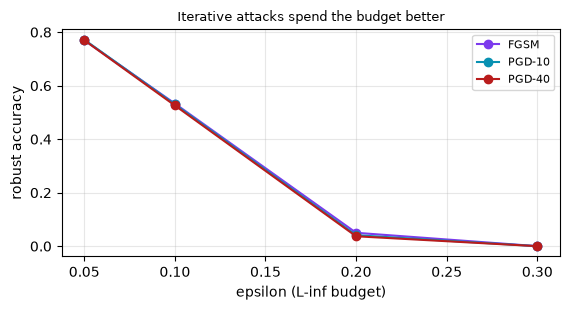

In [5]:
fig, ax = plt.subplots(figsize=(5.8, 3.2))
for column, colour in [("FGSM", "#7c3aed"), ("PGD-10", "#0891b2"), ("PGD-40", "#b91c1c")]:
    ax.plot(comparison.epsilon, comparison[column], "o-", label=column, color=colour)
ax.set_xlabel("epsilon (L-inf budget)")
ax.set_ylabel("robust accuracy")
ax.set_title("Iterative attacks spend the budget better", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — three descending curves with PGD-40 lowest throughout. The gap between FGSM and PGD is
the measure of how much a one-step approximation understates the attacker.

### Step 4 — The mistake: forget the projection

The same loop without the clipping step still "works" and reports a much worse robust accuracy. It is also
using an unbounded budget, which makes the number unusable.

In [6]:
def pgd_unbounded(model, x, y, eps=0.2, alpha=0.05, steps=10):
    x_adv = x.clone()
    for _ in range(steps):
        x_adv = x_adv.clone().requires_grad_(True)
        loss = loss_fn(model(x_adv), y)
        (grad,) = torch.autograd.grad(loss, x_adv)
        x_adv = (x_adv + alpha * grad.sign()).detach().clamp(0, 1)
    return x_adv


x_bad = pgd_unbounded(model, X_te, y_te)
print(f"robust accuracy (no projection): {accuracy_on(x_bad, y_te):.3f}")
print(f"actual L-inf used             : {float((x_bad - X_te).abs().max()):.3f}")
print(f"declared budget               : 0.200")
assert float((x_bad - X_te).abs().max()) > 0.2

robust accuracy (no projection): 0.000
actual L-inf used             : 0.500
declared budget               : 0.200


**Expected output** — a lower "robust accuracy" with an actual perturbation far above 0.2. The assertion
documents the bug: the attack exceeded its declared budget. This is the single most common error in
student robustness reports.

## Exercises

1. **Add restarts.** Run PGD-10 with `restarts=5` and report the change. What does a small change imply
   about the loss surface?
2. **Tune alpha.** Fix ε = 0.2 and sweep α from 0.005 to 0.2. Plot robust accuracy and identify where the
   attack becomes unstable.
3. **Attack in $L_2$.** Replace the sign step with gradient normalisation and rescale to an $L_2$ budget of
   1.0. Report robust accuracy and the actual $L_2$ used.
4. **Write the sentence.** Draft the one-sentence robustness claim you could defend from these numbers, and
   the sentence you could not.

## Reflection questions

1. Why is a single number for robust accuracy almost always misleading?
2. The unbounded attack produced a stronger result. Why is reporting it a failure of method rather than a
   success of attack?
3. Modules 06 and 08 both measure evasion. What does this notebook add that the FGSM notebook cannot?

## References

1. Madry, A. et al., "Towards Deep Learning Models Resistant to Adversarial Attacks", ICLR 2018.
2. Kurakin, A., Goodfellow, I. and Bengio, S., "Adversarial examples in the physical world", 2017.
3. Croce, F. and Hein, M., "Reliable Evaluation of Adversarial Robustness", ICML 2020.
4. Carlini, N. et al., "On Evaluating Adversarial Robustness", 2019.